In [2]:
from pathlib import Path

PROJECT = Path("/content/avocado_ripening_classification")

folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "src",
    "models",
    "report"
]

for folder in folders:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)

print("Project folders created successfully!")
print("Project location:", PROJECT)

Project folders created successfully!
Project location: /content/avocado_ripening_classification


In [3]:
for path in sorted(PROJECT.rglob("*")):
    print(path.relative_to(PROJECT))

data
data/processed
data/raw
models
notebooks
report
src


In [1]:
!pip -q install gdown

import gdown

file_id = "1NMJ0FOxcWH1mwFFeERuY6fgEY-MVgeET"

output = "/content/avocado_dataset"

gdown.download(
    id=file_id,
    output=output,
    quiet=False,
    fuzzy=True
)


Downloading...
From (original): https://drive.google.com/uc?id=1NMJ0FOxcWH1mwFFeERuY6fgEY-MVgeET
From (redirected): https://drive.google.com/uc?id=1NMJ0FOxcWH1mwFFeERuY6fgEY-MVgeET&confirm=t&uuid=906c3413-6db7-4f30-a4c2-515e1bc49b35
To: /content/avocado_dataset
100%|██████████| 145M/145M [00:03<00:00, 41.9MB/s]


'/content/avocado_dataset'

In [4]:
from pathlib import Path

for file in Path("/content").iterdir():
    if file.is_file():
        print(file.name, "-", round(file.stat().st_size / (1024 * 1024), 2), "MB")

avocado_dataset - 138.18 MB


In [5]:
from pathlib import Path
import zipfile
import tarfile
import shutil

project = Path("/content/avocado_ripening_classification")
raw_dir = project / "data" / "raw"

downloaded = Path("/content/avocado_dataset")

# Find the downloaded file
if not downloaded.exists():
    matches = list(Path("/content").glob("avocado_dataset*"))
    if not matches:
        raise FileNotFoundError("Dataset not found. Check the download or upload.")
    downloaded = matches[0]

# Extract according to actual file format
if zipfile.is_zipfile(downloaded):
    with zipfile.ZipFile(downloaded) as z:
        z.extractall(raw_dir)
elif tarfile.is_tarfile(downloaded):
    with tarfile.open(downloaded) as t:
        t.extractall(raw_dir, filter="data")
else:
    print("Downloaded file is not a ZIP or TAR archive.")
    print("File:", downloaded)
    raise ValueError("Check the dataset format before continuing.")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [6]:
from pathlib import Path
from collections import Counter

raw_dir = Path("/content/avocado_ripening_classification/data/raw")

extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

print("DATASET FOLDER STRUCTURE")
print("=" * 45)

for folder in sorted(raw_dir.rglob("*")):
    if folder.is_dir():
        images = [
            f for f in folder.iterdir()
            if f.is_file() and f.suffix.lower() in extensions
        ]
        print(f"{folder.relative_to(raw_dir)}: {len(images)} images")

all_images = [
    f for f in raw_dir.rglob("*")
    if f.is_file() and f.suffix.lower() in extensions
]

print("\nTotal images found:", len(all_images))

DATASET FOLDER STRUCTURE
test: 0 images
test/blackspot: 22 images
test/canker: 22 images
test/fresh: 33 images
test/grenning: 22 images
train: 0 images
train/blackspot: 184 images
train/canker: 179 images
train/fresh: 281 images
train/grenning: 347 images

Total images found: 1090


In [7]:
!pip -q install opencv-python-headless scikit-image scikit-learn seaborn

In [8]:
from pathlib import Path
from PIL import Image, ImageFile
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random

PROJECT = Path("/content/avocado_ripening_classification")
RAW_DIR = PROJECT / "data" / "raw"

CLASSES = ["blackspot", "canker", "fresh", "grenning"]
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("Libraries imported successfully!")

Libraries imported successfully!


Split      test  train
Class                 
blackspot    22    184
canker       22    179
fresh        33    281
grenning     22    347


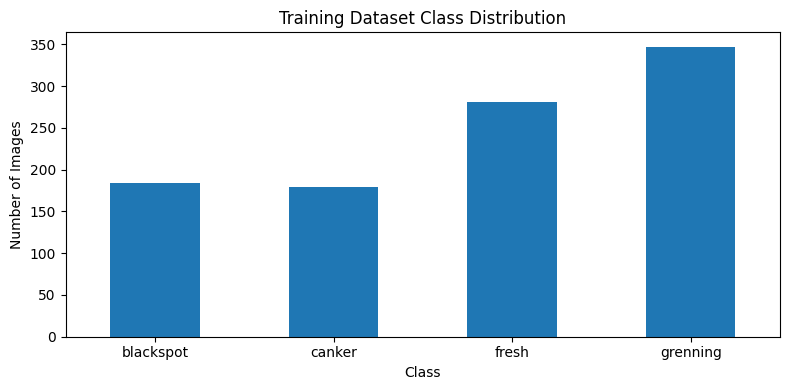

Training class percentages:
Class
blackspot    18.57
canker       18.06
fresh        28.36
grenning     35.02
Name: Images, dtype: float64


In [9]:
train_dir = RAW_DIR / "train"
test_dir = RAW_DIR / "test"

rows = []

for split_dir in [train_dir, test_dir]:
    for class_name in CLASSES:
        folder = split_dir / class_name
        count = sum(
            1 for p in folder.iterdir()
            if p.is_file() and p.suffix.lower() in EXTENSIONS
        )
        rows.append({
            "Split": split_dir.name,
            "Class": class_name,
            "Images": count
        })

df = pd.DataFrame(rows)
print(df.pivot(index="Class", columns="Split", values="Images"))

train_counts = df[df["Split"] == "train"].set_index("Class")["Images"]

plt.figure(figsize=(8, 4))
train_counts.plot(kind="bar")
plt.title("Training Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Training class percentages:")
print((train_counts / train_counts.sum() * 100).round(2))

In [10]:
records = []
bad_images = []

for split in ["train", "test"]:
    for class_name in CLASSES:
        folder = RAW_DIR / split / class_name

        for path in folder.iterdir():
            if not path.is_file() or path.suffix.lower() not in EXTENSIONS:
                continue

            try:
                with Image.open(path) as img:
                    img.verify()

                with Image.open(path) as img:
                    width, height = img.size
                    records.append({
                        "split": split,
                        "class": class_name,
                        "file": str(path),
                        "width": width,
                        "height": height,
                        "aspect_ratio": width / height,
                        "file_size_kb": path.stat().st_size / 1024
                    })

            except Exception:
                bad_images.append(str(path))

image_df = pd.DataFrame(records)

print("Valid images:", len(image_df))
print("Unreadable images:", len(bad_images))
print("\nImage dimensions:")
print(image_df[["width", "height"]].describe())

print("\nSmallest images:")
print(image_df.nsmallest(10, "width")[["class", "file", "width", "height"]])

print("\nRepeated file contents:")
hashes = {}
duplicates = []

import hashlib

for path in image_df["file"]:
    digest = hashlib.md5(Path(path).read_bytes()).hexdigest()
    if digest in hashes:
        duplicates.append((path, hashes[digest]))
    else:
        hashes[digest] = path

print("Exact duplicate pairs:", len(duplicates))

Valid images: 1090
Unreadable images: 0

Image dimensions:
             width       height
count  1090.000000  1090.000000
mean    669.022018   659.438532
std     211.551046   224.984294
min     144.000000   138.000000
25%     454.500000   400.000000
50%     800.000000   800.000000
75%     800.000000   800.000000
max     800.000000   800.000000

Smallest images:
      class                                               file  width  height
526   fresh  /content/avocado_ripening_classification/data/...    144     176
635   fresh  /content/avocado_ripening_classification/data/...    144     176
503   fresh  /content/avocado_ripening_classification/data/...    154     140
593   fresh  /content/avocado_ripening_classification/data/...    154     140
409   fresh  /content/avocado_ripening_classification/data/...    160     154
408   fresh  /content/avocado_ripening_classification/data/...    170     138
367   fresh  /content/avocado_ripening_classification/data/...    174     158
440   fresh

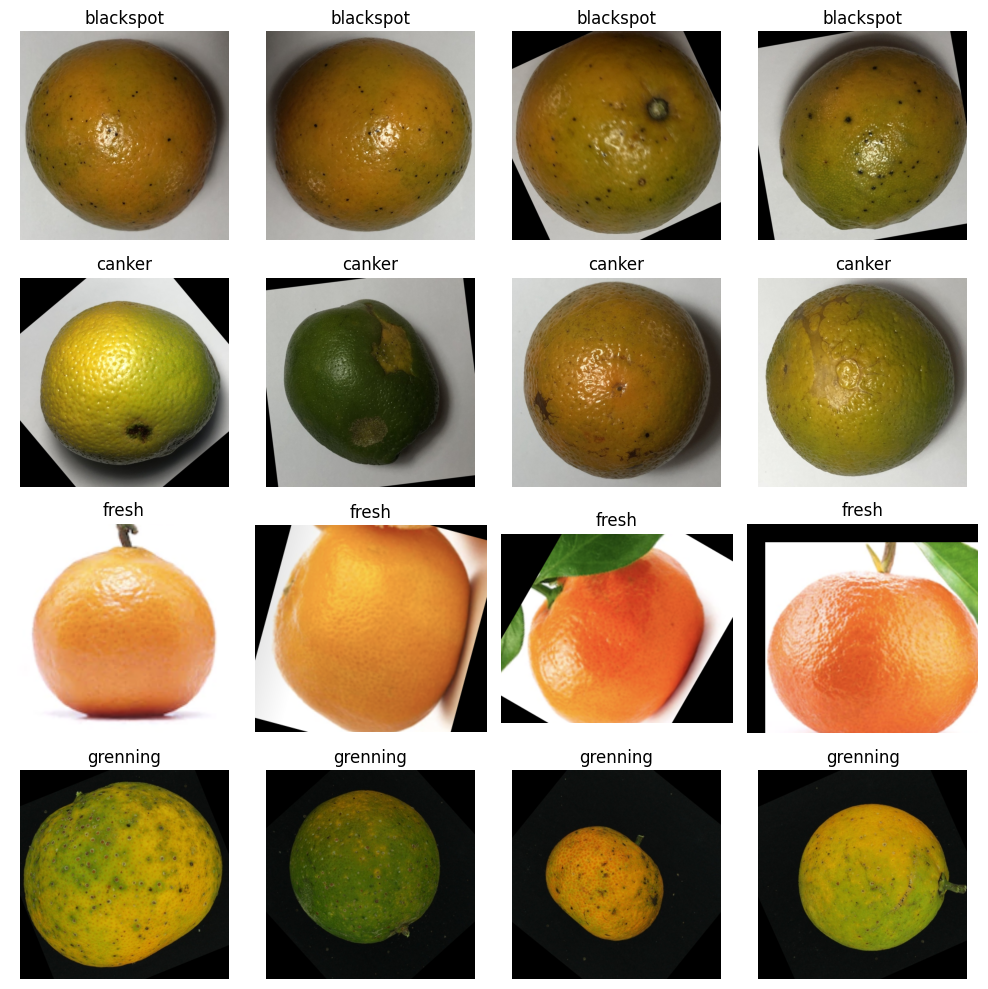

In [11]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
random.seed(42)

for row, class_name in enumerate(CLASSES):
    files = [
        p for p in (train_dir / class_name).iterdir()
        if p.is_file() and p.suffix.lower() in EXTENSIONS
    ]

    samples = random.sample(files, min(4, len(files)))

    for col, ax in enumerate(axes[row]):
        ax.axis("off")

        if col < len(samples):
            with Image.open(samples[col]) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(class_name)

plt.tight_layout()
plt.show()

In [12]:
eda_dir = PROJECT / "report"
eda_dir.mkdir(exist_ok=True)

df.to_csv(eda_dir / "class_distribution.csv", index=False)
image_df.to_csv(eda_dir / "image_quality_analysis.csv", index=False)

print("EDA results saved in:", eda_dir)

EDA results saved in: /content/avocado_ripening_classification/report


In [13]:
import cv2
import numpy as np
import joblib

from pathlib import Path
from skimage.feature import local_binary_pattern
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

PROJECT = Path("/content/avocado_ripening_classification")
RAW_DIR = PROJECT / "data" / "raw"
MODEL_DIR = PROJECT / "models"
MODEL_DIR.mkdir(exist_ok=True)

CLASSES = ["blackspot", "canker", "fresh", "grenning"]
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def extract_features(image_path):
    img = cv2.imread(str(image_path))

    if img is None:
        raise ValueError(f"Cannot read image: {image_path}")

    img = cv2.resize(img, (128, 128))

    # Color features: CIELAB histograms
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)

    hist_l = cv2.calcHist([lab], [0], None, [16], [0, 256])
    hist_a = cv2.calcHist([lab], [1], None, [16], [0, 256])
    hist_b = cv2.calcHist([lab], [2], None, [16], [0, 256])

    color_features = np.concatenate(
        [hist_l.flatten(), hist_a.flatten(), hist_b.flatten()]
    )

    # Texture features: Local Binary Patterns
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")

    texture_features, _ = np.histogram(
        lbp.ravel(), bins=np.arange(0, 12), range=(0, 11)
    )

    texture_features = texture_features.astype(float)
    texture_features /= texture_features.sum() + 1e-8

    return np.concatenate([color_features, texture_features])

def load_features(split):
    X, y = [], []

    for label in CLASSES:
        folder = RAW_DIR / split / label

        for path in sorted(folder.iterdir()):
            if path.is_file() and path.suffix.lower() in EXTENSIONS:
                try:
                    X.append(extract_features(path))
                    y.append(label)
                except (ValueError, cv2.error) as error:
                    print("Skipping unreadable image:", path.name, error)

    return np.asarray(X), np.asarray(y)

print("Extracting training features...")
X_all, y_all = load_features("train")

print("Extracting test features...")
X_test, y_test = load_features("test")

X_train, X_val, y_train, y_val = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    random_state=42,
    stratify=y_all
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

# Standardization is fitted only on training data
svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", class_weight="balanced")
)

print("\nTraining SVM...")
svm_model.fit(X_train, y_train)

val_pred = svm_model.predict(X_val)

print("\nCLASSICAL MODEL — VALIDATION RESULTS")
print("Accuracy:", round(accuracy_score(y_val, val_pred), 4))
print(classification_report(
    y_val, val_pred, labels=CLASSES, zero_division=0
))

joblib.dump(svm_model, MODEL_DIR / "classical_svm.joblib")

print("Classical model saved successfully!")

Extracting training features...
Extracting test features...
Training samples: 792
Validation samples: 199
Test samples: 99

Training SVM...

CLASSICAL MODEL — VALIDATION RESULTS
Accuracy: 0.9648
              precision    recall  f1-score   support

   blackspot       0.89      0.92      0.91        37
      canker       0.91      0.89      0.90        36
       fresh       1.00      1.00      1.00        56
    grenning       1.00      1.00      1.00        70

    accuracy                           0.96       199
   macro avg       0.95      0.95      0.95       199
weighted avg       0.96      0.96      0.96       199

Classical model saved successfully!


In [14]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from pathlib import Path
import numpy as np
import copy
import joblib

PROJECT = Path("/content/avocado_ripening_classification")
RAW_DIR = PROJECT / "data" / "raw"
MODEL_DIR = PROJECT / "models"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ImageNet normalization for the pretrained model
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Separate dataset instances ensure validation uses no augmentation
train_base = datasets.ImageFolder(str(RAW_DIR / "train"))
train_aug = datasets.ImageFolder(
    str(RAW_DIR / "train"), transform=train_transform
)
train_eval = datasets.ImageFolder(
    str(RAW_DIR / "train"), transform=eval_transform
)
test_data = datasets.ImageFolder(
    str(RAW_DIR / "test"), transform=eval_transform
)

class_names = train_base.classes
print("Classes:", class_names)
print("Training images:", len(train_base))
print("Test images:", len(test_data))

indices = np.arange(len(train_base))
train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=train_base.targets
)

train_data = Subset(train_aug, train_idx)
val_data = Subset(train_eval, val_idx)

train_loader = DataLoader(
    train_data, batch_size=32, shuffle=True, num_workers=2
)
val_loader = DataLoader(
    val_data, batch_size=32, shuffle=False, num_workers=2
)

# Load pretrained MobileNetV2
try:
    weights = models.MobileNet_V2_Weights.DEFAULT
    model = models.mobilenet_v2(weights=weights)
except Exception as e:
    print("Pretrained weight download failed:", e)
    raise RuntimeError(
        "MobileNetV2 pretrained weights are required. "
        "Check internet access in Colab and rerun."
    )

# Freeze pretrained feature extractor
for param in model.features.parameters():
    param.requires_grad = False

# Replace the classification head
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, len(class_names))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.classifier.parameters(), lr=0.001
)

best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())

# Short training run to fit the deadline
EPOCHS = 3

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    avg_train_loss = train_loss / len(train_data)
    avg_val_loss = val_loss / len(val_data)
    val_accuracy = correct / total

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train loss: {avg_train_loss:.4f} | "
        f"Val loss: {avg_val_loss:.4f} | "
        f"Val accuracy: {val_accuracy:.4f}"
    )

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_state = copy.deepcopy(model.state_dict())

model.load_state_dict(best_state)
model.eval()

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names
}, MODEL_DIR / "mobilenetv2.pth")

print("MobileNetV2 model saved successfully!")

Device: cuda
Classes: ['blackspot', 'canker', 'fresh', 'grenning']
Training images: 991
Test images: 99
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 85.5MB/s]


Epoch 1/3 | Train loss: 0.8628 | Val loss: 0.5054 | Val accuracy: 0.9347
Epoch 2/3 | Train loss: 0.3750 | Val loss: 0.3022 | Val accuracy: 0.9648
Epoch 3/3 | Train loss: 0.2231 | Val loss: 0.2266 | Val accuracy: 0.9799
MobileNetV2 model saved successfully!



Classical SVM (CIELAB + LBP) — TEST RESULTS
              precision    recall  f1-score   support

   blackspot       0.85      1.00      0.92        22
      canker       1.00      0.82      0.90        22
       fresh       1.00      1.00      1.00        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.96        99
   macro avg       0.96      0.95      0.95        99
weighted avg       0.97      0.96      0.96        99


MobileNetV2 — TEST RESULTS
              precision    recall  f1-score   support

   blackspot       0.87      0.91      0.89        22
      canker       0.89      0.73      0.80        22
       fresh       0.92      1.00      0.96        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.92        99
   macro avg       0.92      0.91      0.91        99
weighted avg       0.92      0.92      0.92        99


FINAL TEST COMPARISON


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Classical SVM (CIELAB + LBP),0.9596,0.9615,0.9545,0.9542
1,MobileNetV2,0.9192,0.9188,0.9091,0.9114


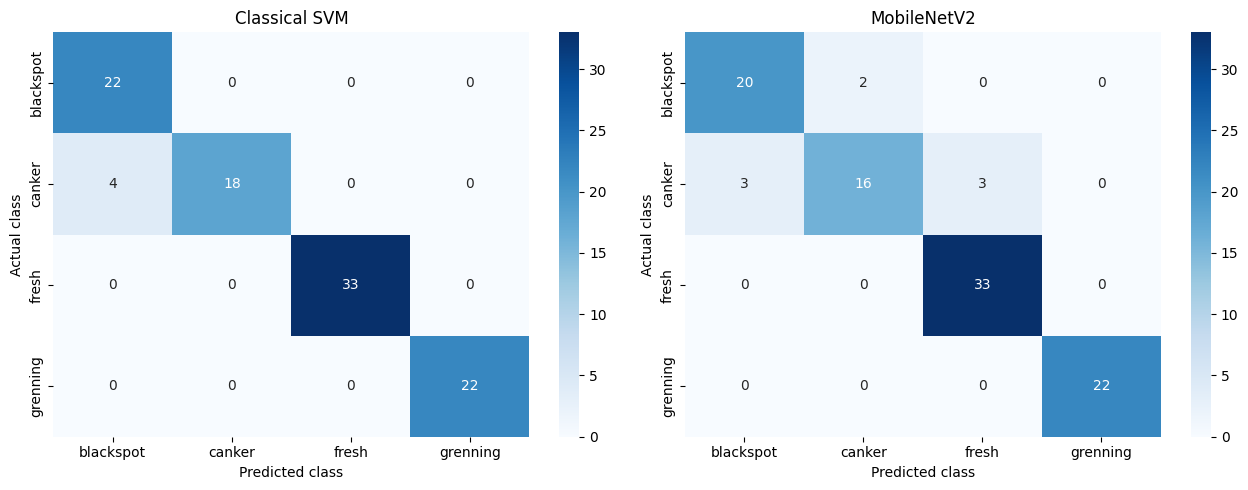

Evaluation results saved successfully.


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert numeric test labels to class names
y_true_names = np.array([
    test_data.classes[i] for i in y_true
])

# SVM already predicts class names
svm_pred_names = np.asarray(svm_predictions).astype(str)

# Convert MobileNetV2 numeric predictions to class names
dl_pred_names = np.array([
    class_names[i] for i in dl_predictions
])

results = []

for name, predictions in [
    ("Classical SVM (CIELAB + LBP)", svm_pred_names),
    ("MobileNetV2", dl_pred_names)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true_names, predictions),
        "Macro Precision": precision_score(
            y_true_names, predictions,
            labels=class_names, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true_names, predictions,
            labels=class_names, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true_names, predictions,
            labels=class_names, average="macro", zero_division=0
        )
    })

    print(f"\n{name} — TEST RESULTS")
    print(classification_report(
        y_true_names,
        predictions,
        labels=class_names,
        zero_division=0
    ))

comparison = pd.DataFrame(results)

print("\nFINAL TEST COMPARISON")
display(comparison.round(4))

comparison.to_csv(
    REPORT_DIR / "model_comparison.csv",
    index=False
)

# Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name, predictions in [
    (axes[0], "Classical SVM", svm_pred_names),
    (axes[1], "MobileNetV2", dl_pred_names)
]:
    cm = confusion_matrix(
        y_true_names, predictions, labels=class_names
    )

    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names, ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

plt.tight_layout()
plt.savefig(
    REPORT_DIR / "confusion_matrices.png",
    dpi=150
)
plt.show()

print("Evaluation results saved successfully.")

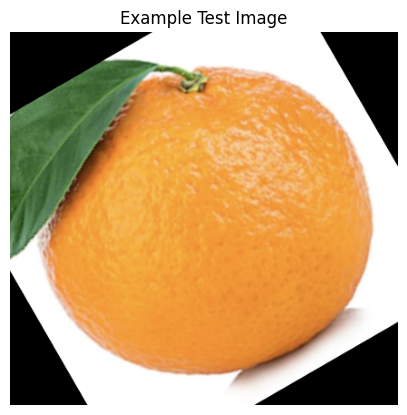

Actual dataset label: fresh
Classical SVM prediction: fresh
MobileNetV2 prediction: fresh
MobileNetV2 predicted-class score: 0.963


In [17]:
import random
import matplotlib.pyplot as plt
from PIL import Image
import torch
import numpy as np

# Select one test image
idx = random.randrange(len(test_data.samples))
image_path, actual_idx = test_data.samples[idx]
actual_class = test_data.classes[actual_idx]

# Approach 1: Classical SVM
features = extract_features(image_path).reshape(1, -1)
svm_prediction = svm_model.predict(features)[0]

# Approach 2: MobileNetV2
input_tensor, _ = test_data[idx]

dl_model.eval()
with torch.no_grad():
    logits = dl_model(input_tensor.unsqueeze(0).to(device))
    probs = torch.softmax(logits, dim=1)[0]
    dl_idx = int(logits.argmax(dim=1).item())

dl_prediction = class_names[dl_idx]

# Display example
plt.figure(figsize=(5, 5))
plt.imshow(Image.open(image_path).convert("RGB"))
plt.axis("off")
plt.title("Example Test Image")
plt.show()

print("Actual dataset label:", actual_class)
print("Classical SVM prediction:", svm_prediction)
print("MobileNetV2 prediction:", dl_prediction)
print("MobileNetV2 predicted-class score:", round(probs[dl_idx].item(), 4))

In [18]:
report = """
# Greenpod Labs — Assignment 2
## Computer Vision Classification

### 1. Objective
Build and compare two computer vision approaches for image classification.

### 2. Dataset Understanding
The supplied dataset contains 1,090 images across four labels:
blackspot, canker, fresh, and grenning.

Training images: 991
Test images: 99

Training distribution:
- blackspot: 184 (18.57%)
- canker: 179 (18.06%)
- fresh: 281 (28.36%)
- grenning: 347 (35.02%)

All 1,090 images were readable. No exact duplicate image pairs
were found by the file-content check. Image dimensions varied,
with widths from 144 to 800 pixels and heights from 138 to 800 pixels.

Visual inspection found differences in lighting, orientation,
background, and image appearance. Some examples labelled fresh
appear to show oranges rather than avocados. Therefore, the supplied
dataset does not establish the four avocado ripening stages described
in the assignment. The models below classify the dataset's actual
labels, not verified avocado ripening stages.

### 3. Approach 1 — Classical Computer Vision
CIELAB color histograms and Local Binary Pattern (LBP) texture
features were extracted from resized images. A standardized
RBF-kernel Support Vector Machine (SVM) was trained on these features.

Validation accuracy: 96.48%

### 4. Approach 2 — MobileNetV2
A pretrained MobileNetV2 model was used for transfer learning.
The feature extractor was frozen, and the final classification
layer was trained for four dataset classes over three epochs.

Validation accuracy: 97.99%

### 5. Test Results

| Metric | Classical SVM | MobileNetV2 |
|---|---:|---:|
| Accuracy | 95.96% | 91.92% |
| Macro Precision | 96.15% | 91.88% |
| Macro Recall | 95.45% | 90.91% |
| Macro F1-score | 95.42% | 91.14% |

The classical SVM performed better on the held-out test set.
Its macro F1-score was 95.42%, compared with 91.14% for MobileNetV2.

The test set contains only 99 images, so these estimates may vary
on a larger, more diverse dataset.

### 6. Evaluation Metrics
Accuracy measures the proportion of correct predictions.
Precision measures how often predictions for a class are correct.
Recall measures how many actual examples of a class are identified.
Macro F1-score gives equal weight to each class and is useful when
class sizes differ. Confusion matrices show which classes are confused.

### 7. Example Demonstration
The accompanying notebook runs one held-out test image through
both models and prints the actual dataset label and each prediction.
The recorded output should be retained as demonstration evidence.

### 8. Mandatory Questions

#### 1. In production, how does your model perform?
On the supplied held-out test set, SVM achieved 95.96% accuracy
and 95.42% macro F1-score. MobileNetV2 achieved 91.92% accuracy
and 91.14% macro F1-score. Production performance and inference
latency have not been measured. Real-world performance would require
testing on representative images from the intended production setting.

#### 2. What are the drawbacks of your model?
The dataset labels and some sample images do not match the stated
avocado ripening task. The test set is small. Differences in lighting,
background, image resolution, and surface appearance may affect
predictions. The SVM depends on manually designed color and texture
features, while MobileNetV2 may require more training data and tuning.

#### 3. If given more time, what would you improve?
Obtain a verified avocado dataset labelled by ripening stage.
Inspect labels and image quality, collect more balanced samples,
test under different lighting conditions, tune both models, and
evaluate them on an independent real-world dataset. Measure inference
latency before selecting a production deployment model.

#### 4. Where did you spend the most time?
The main effort was spent on dataset inspection and preprocessing,
implementing two different approaches, training the models, resolving
label-format issues during evaluation, and comparing the test metrics.

### 9. Conclusion
Both approaches were implemented and evaluated. Classical SVM was
the stronger model on this dataset's held-out test set. However,
the dataset mismatch must be resolved before either model can be
claimed to solve avocado ripening-stage classification.
"""

report_path = PROJECT / "report" / "Assignment2_Avocado_Report.md"
report_path.write_text(report.strip(), encoding="utf-8")

print("Report created:", report_path)
print("Please review the report and retain the example prediction output.")

Report created: /content/avocado_ripening_classification/report/Assignment2_Avocado_Report.md
Please review the report and retain the example prediction output.


In [19]:
import zipfile

zip_path = Path("/content/avocado_ripening_classification.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in PROJECT.rglob("*"):
        if path.is_file():
            z.write(path, path.relative_to(PROJECT.parent))

print("Project ZIP created:", zip_path)

Project ZIP created: /content/avocado_ripening_classification.zip


In [20]:
from google.colab import files
files.download("/content/avocado_ripening_classification.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>